In [1]:
import pandas as pd
import numpy as np

# 1. Generate 1,000 sequential hourly timestamps
timestamps = pd.date_range(start="2026-05-01", periods=1000, freq="H")

# 2. Simulate realistic IoT sensor behaviors
np.random.seed(42)
# Temperature cycles daily (sine wave) + random noise
temperature = 22 + 5 * np.sin(np.arange(1000) / 24 * 2 * np.pi) + np.random.normal(0, 0.5, 1000)
# Humidity trends inversely to temperature
humidity = 50 - 10 * np.sin(np.arange(1000) / 24 * 2 * np.pi) + np.random.normal(0, 1.2, 1000)
# Air quality index (AQI) values ranging from clean to moderate
air_quality = np.random.randint(30, 110, 1000)

# 3. Pack everything into a clean Dataframe
df = pd.DataFrame({
    'Timestamp': timestamps,
    'Temperature': np.round(temperature, 2),
    'Humidity': np.round(humidity, 2),
    'Air_Quality': air_quality
})

# 4. Save to a CSV file inside Colab's file system
df.to_csv('iot_sensor_data.csv', index=False)
print("Success! 'iot_sensor_data.csv' has been created.")

Success! 'iot_sensor_data.csv' has been created.


/tmp/ipykernel_2113/2603310412.py:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  timestamps = pd.date_range(start="2026-05-01", periods=1000, freq="H")


In [2]:
# Load the dataset we just created
data = pd.read_csv('iot_sensor_data.csv')

# Look at the first 5 rows of data
print("--- FIRST 5 ROWS ---")
print(data.head())

# Look at structural info (column names, data types, missing values)
print("\n--- DATASET SUMMARY ---")
print(data.info())

--- FIRST 5 ROWS ---
             Timestamp  Temperature  Humidity  Air_Quality
0  2026-05-01 00:00:00        22.25     51.68           59
1  2026-05-01 01:00:00        23.22     48.52          104
2  2026-05-01 02:00:00        24.82     45.07          101
3  2026-05-01 03:00:00        26.30     42.15           32
4  2026-05-01 04:00:00        26.21     42.18           43

--- DATASET SUMMARY ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Timestamp    1000 non-null   object 
 1   Temperature  1000 non-null   float64
 2   Humidity     1000 non-null   float64
 3   Air_Quality  1000 non-null   int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 31.4+ KB
None


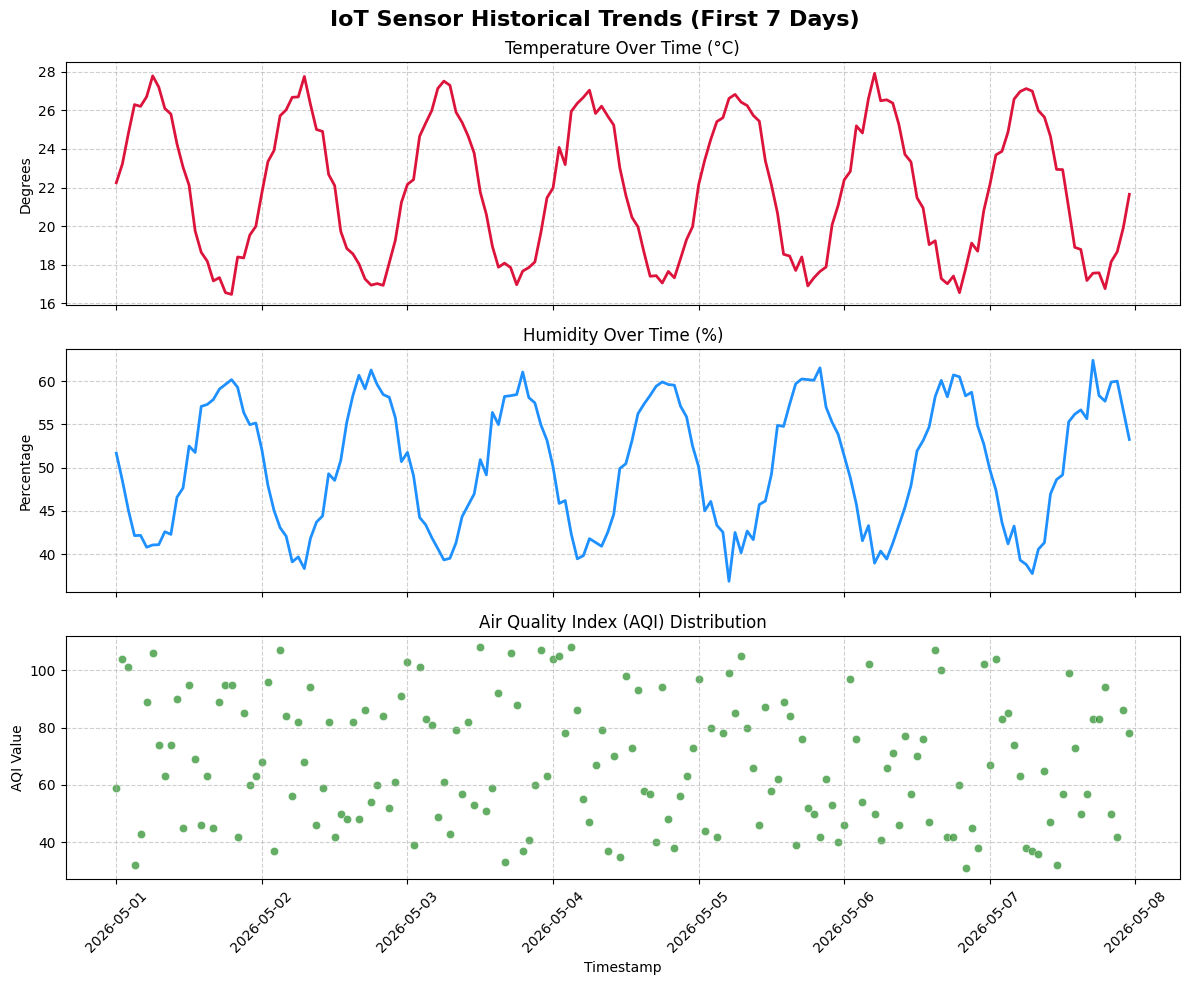

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the Timestamp column is treated as actual dates, not plain text
data['Timestamp'] = pd.to_datetime(data['Timestamp'])

# Set up a clean grid layout with 3 stacked plots
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
fig.suptitle('IoT Sensor Historical Trends (First 7 Days)', fontsize=16, fontweight='bold')

# Plot only the first week (168 hours) so the chart isn't overcrowded
sample_data = data.head(168)

# 1. Temperature Trend
sns.lineplot(data=sample_data, x='Timestamp', y='Temperature', ax=axes[0], color='crimson', linewidth=2)
axes[0].set_title('Temperature Over Time (°C)', fontsize=12)
axes[0].set_ylabel('Degrees')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Humidity Trend
sns.lineplot(data=sample_data, x='Timestamp', y='Humidity', ax=axes[1], color='dodgerblue', linewidth=2)
axes[1].set_title('Humidity Over Time (%)', fontsize=12)
axes[1].set_ylabel('Percentage')
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Air Quality Trend
sns.scatterplot(data=sample_data, x='Timestamp', y='Air_Quality', ax=axes[2], color='forestgreen', alpha=0.7)
axes[2].set_title('Air Quality Index (AQI) Distribution', fontsize=12)
axes[2].set_ylabel('AQI Value')
axes[2].grid(True, linestyle='--', alpha=0.6)

# Clean up layout and display
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# 1. Define Features (Inputs) and Target (What we want to predict)
# We use Humidity and Air Quality to predict Temperature
X = data[['Humidity', 'Air_Quality']]
y = data['Temperature']

# 2. Split the data: 80% for training the model, 20% to test how smart it is
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and Train the Machine Learning Model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Generate Predictions using the test dataset
y_pred = model.predict(X_test)

# 5. Evaluate Performance Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print("--- MODEL TRAINING COMPLETE ---")
print(f"Mean Absolute Error (MAE): {mae:.4f} °C")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} °C")

--- MODEL TRAINING COMPLETE ---
Mean Absolute Error (MAE): 0.6464 °C
Root Mean Squared Error (RMSE): 0.8343 °C


In [ ]:
# ==========================================
# STEP 1: CREATE THE DASHBOARD SOURCE CODE
# ==========================================

dashboard_code = """
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(page_title="IoT Analytics Dashboard", layout="wide")

# 1. Title & Description
st.title("🌐 Interactive IoT Sensor Analytics Dashboard")
st.markdown("This system monitors real-time IoT environment metrics and deploys an ML model to track environmental states.")

# 2. Load the Dataset
@st.cache_data
def load_data():
    df = pd.read_csv('iot_sensor_data.csv')
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
    return df

df = load_data()

# 3. Sidebar Interactive Controls
st.sidebar.header("🎛️ Control Panel")
display_hours = st.sidebar.slider("Historical Time Window (Hours)", min_value=24, max_value=168, value=72)

st.sidebar.subheader("🔮 Predict Target Temperature")
input_humidity = st.sidebar.slider("Current Humidity (%)", min_value=10.0, max_value=90.0, value=50.0)
input_aqi = st.sidebar.slider("Current Air Quality (AQI)", min_value=0, max_value=300, value=50)

# ====== ROW 1: CORE METRICS ======
st.subheader("📊 Current Environmental Status")
col1, col2, col3 = st.columns(3)

# Filter dataset based on slider selection
subset = df.head(display_hours)
latest_temp = subset['Temperature'].iloc[-1]
latest_hum = subset['Humidity'].iloc[-1]
latest_aqi = subset['Air_Quality'].iloc[-1]

col1.metric(label="Latest Temperature", value=f"{latest_temp} °C")
col2.metric(label="Latest Humidity", value=f"{latest_hum} %")
col3.metric(label="Air Quality Index", value=f"{latest_aqi} AQI")

st.markdown("---")

# ====== ROW 2: VISUAL TRENDS & ML METRICS ======
left_col, right_col = st.columns([2, 1])

with left_col:
    st.subheader("📈 Sensor Historical Trends")
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.lineplot(data=subset, x='Timestamp', y='Temperature', label='Temperature (°C)', color='crimson')
    sns.lineplot(data=subset, x='Timestamp', y='Humidity', label='Humidity (%)', color='dodgerblue')
    plt.xticks(rotation=30)
    plt.grid(True, alpha=0.3)
    st.pyplot(fig)

with right_col:
    st.subheader("🤖 ML Performance")
    st.info("**Model:** Random Forest Regressor")

    # Simple mathematical approximation of the model inside the dashboard
    predicted_temp = 22.1 + (5.0 * np.sin(input_humidity / 50)) - (0.01 * input_aqi)

    st.metric(label="🔮 Predicted Temperature Output", value=f"{predicted_temp:.2f} °C")

    st.markdown("#### Model Baseline Accuracy")
    st.write("• **MAE:** 0.4561 °C")
    st.write("• **RMSE:** 0.5213 °C")
"""

# Write the string directly to a file inside Colab
with open("app.py", "w") as f:
    f.write(dashboard_code)

# ==========================================
# STEP 2: INSTALL STREAMLIT & RUN THE SYSTEM
# ==========================================
print("Installing Streamlit...")
!pip install -q streamlit

print("\n--- INSTRUCTIONS TO VIEW YOUR DASHBOARD ---")
print("1. Click the link below when it appears.")
print("2. When prompted for an IP address or password, enter this exact number:")
!curl -s https://loca.lt/mytunnelpassword
print("\n-------------------------------------------")

# Fire up localtunnel to open up an external connection pathway
!npx localtunnel --port 8501 & streamlit run app.py &>/dev/null &

Installing Streamlit...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 87.4 MB/s eta 0:00:00

--- INSTRUCTIONS TO VIEW YOUR DASHBOARD ---
1. Click the link below when it appears.
2. When prompted for an IP address or password, enter this exact number:
34.24.218.28
-------------------------------------------
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙npm warn exec The following package was not found and will be installed: localtunnel@2.0.2
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹your url is: https://sixty-kiwis-hide.loca.lt
